In [1]:
# Compute and compare CLIP embeddings of image–text pairs

In [13]:
import numpy as np
import open_clip
import torch
import umap.plot
from PIL import Image

In [2]:
model, _, preprocess = open_clip.create_model_and_transforms('ViT-B-32', pretrained='laion2b_s34b_b79k')
model.eval()  # model in train mode by default, impacts some models with BatchNorm or stochastic depth active
tokenizer = open_clip.get_tokenizer('ViT-B-32')


In [7]:
# Example from open CLIP doc
image = preprocess(Image.open("img/CLIP.png")).unsqueeze(0)
text = tokenizer(["a diagram", "a dog", "a cat"])

with torch.no_grad():
    image_features = model.encode_image(image)
    text_features = model.encode_text(text)
    image_features /= image_features.norm(dim=-1, keepdim=True)
    text_features /= text_features.norm(dim=-1, keepdim=True)

    text_probs = (100.0 * image_features @ text_features.T).softmax(dim=-1)

print("Label probs:", text_probs)
print("The image most likely is \"a diagram\"")

Label probs: tensor([[9.9951e-01, 4.0415e-04, 8.4107e-05]])
The image most likely is "a diagram"


In [46]:
labels = []
samples = []
word_lists = ["nouns", "verbs"]
for file in word_lists:
    with open(f"word_lists/{file}", "r") as f:
        content = f.read().splitlines()
        samples.extend(content)
        labels.extend([file] * len(content))

#print(samples)
#print(labels)

<Axes: >

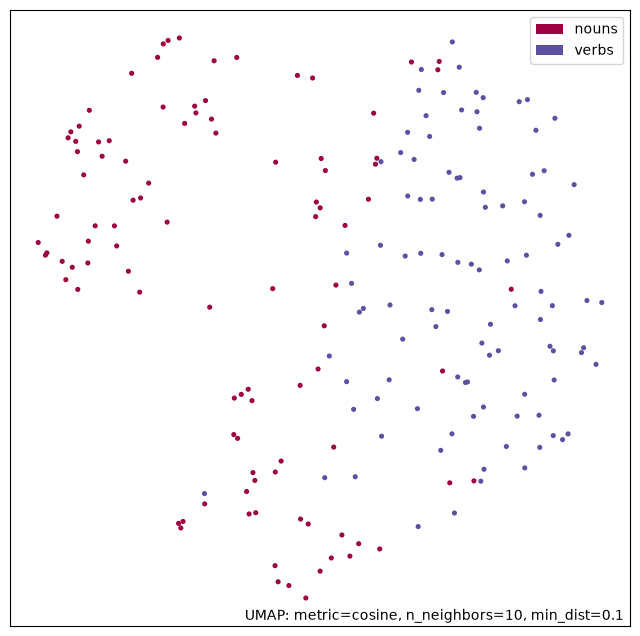

In [47]:
text = tokenizer(samples)

with torch.no_grad():
    text_features = model.encode_text(text)

example = umap.UMAP(
    n_neighbors=10, n_components=2, metric="cosine").fit(text_features)
umap.plot.points(example, labels=np.array(labels))
